In [49]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("sales_data_2000_rows (2) (2).xlsx")

df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410
4,1005,2025-04-12,Mouse,Electronics,Mumbai,NaN,624


In [50]:
df.isnull().sum()

Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    1
Price       0
dtype: int64

In [51]:
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 2000


In [52]:

# Handle missing values
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Calculate Revenue
df["Revenue"] = df["Quantity"] * df["Price"]

print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

Missing Values:
Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    0
Price       0
Revenue     0
dtype: int64
Duplicate Rows: 0


In [53]:
df["Revenue"] = df["Quantity"] * df["Price"]
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0
4,1005,2025-04-12,Mouse,Electronics,Mumbai,3.0,624,1872.0


In [54]:
df.to_excel("cleaned_sales_data.xlsx", index=False)

print("Cleaned dataset saved successfully!")
print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))

Cleaned dataset saved successfully!
Total Rows: 2000
Total Columns: 8


In [55]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())


Missing Values:
Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    0
Price       0
Revenue     0
dtype: int64
Duplicate Rows: 0


In [56]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Date"].dtype

dtype('<M8[us]')

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Order_ID  2000 non-null   int64         
 1   Date      2000 non-null   datetime64[us]
 2   Product   2000 non-null   str           
 3   Category  2000 non-null   str           
 4   City      2000 non-null   str           
 5   Quantity  2000 non-null   float64       
 6   Price     2000 non-null   int64         
 7   Revenue   2000 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(3)
memory usage: 125.1 KB


In [58]:
df["Revenue"] = df["Quantity"] * df["Price"]
df.head()

,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0
4,1005,2025-04-12,Mouse,Electronics,Mumbai,3.0,624,1872.0


In [59]:
print("Total Revenue:", df["Revenue"].sum())

Total Revenue: 51501934.0


In [60]:
product_sales = df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)
print(product_sales)
print("Best-selling Product:", product_sales.idxmax())

Product
Chair       568.0
Sofa        537.0
Notebook    531.0
Bag         529.0
Printer     517.0
Keyboard    509.0
Pen         507.0
Bottle      497.0
Laptop      492.0
Monitor     476.0
Mouse       460.0
Table       449.0
Name: Quantity, dtype: float64
Best-selling Product: Chair


In [61]:
city_sales = df.groupby("City")["Revenue"].sum().sort_values(ascending=False)
print(city_sales)
print("Highest Revenue City:", city_sales.idxmax())

City
Ahmedabad    7449911.0
Delhi        7092644.0
Kolkata      6819173.0
Mumbai       6704675.0
Hyderabad    6565333.0
Chennai      5944069.0
Pune         5764738.0
Bangalore    5161391.0
Name: Revenue, dtype: float64
Highest Revenue City: Ahmedabad


In [62]:
category_sales = df.groupby("Category")["Revenue"].sum().sort_values(ascending=False)
print(category_sales)
print("Best Category:", category_sales.idxmax())

Category
Electronics    37095222.0
Furniture      13343784.0
Accessories      905769.0
Stationery       157159.0
Name: Revenue, dtype: float64
Best Category: Electronics


In [63]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Revenue"].sum()
print(monthly_sales)

Month
2025-01    4021909.0
2025-02    3655339.0
2025-03    4607846.0
2025-04    4785474.0
2025-05    4884091.0
2025-06    3654206.0
2025-07    3979183.0
2025-08    4012286.0
2025-09    4318017.0
2025-10    4428577.0
2025-11    4185989.0
2025-12    4891185.0
2026-01      77832.0
Freq: M, Name: Revenue, dtype: float64


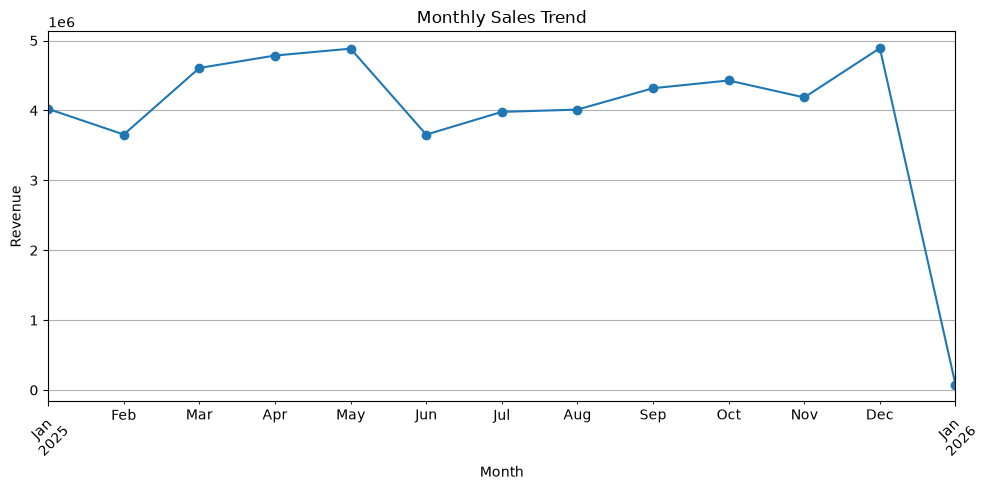

In [64]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

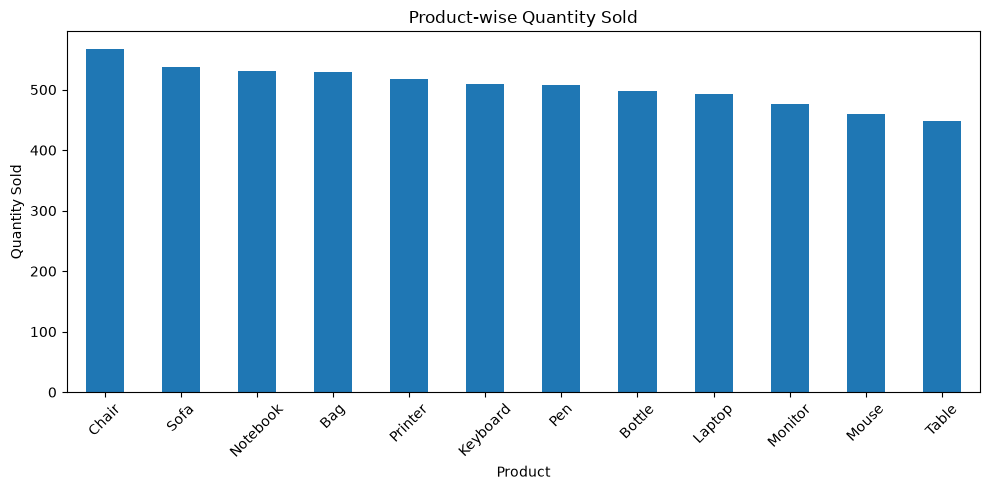

In [65]:
product_sales.plot(kind="bar", figsize=(10, 5))

plt.title("Product-wise Quantity Sold")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

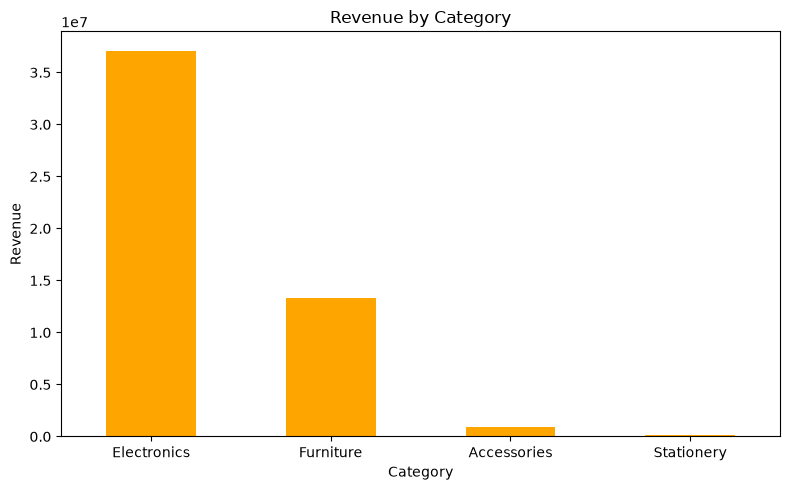

In [66]:
category_sales.plot(kind="bar", color="orange", figsize=(8, 5))

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [67]:
print("Lowest Revenue City:", city_sales.idxmin())
print("Lowest Performing Category:", category_sales.idxmin())
print("Lowest Selling Product:", product_sales.idxmin())

Lowest Revenue City: Bangalore
Lowest Performing Category: Stationery
Lowest Selling Product: Table


In [68]:
print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))
print("Missing Values:")
print(df.isnull().sum())

df.head()

Total Rows: 2000
Total Columns: 9
Missing Values:
Order_ID    0
Date        0
Product     0
Category    0
City        0
Quantity    0
Price       0
Revenue     0
Month       0
dtype: int64


,Order_ID,Date,Product,Category,City,Quantity,Price,Revenue,Month
0,1001,2025-02-19,Printer,Electronics,Kolkata,3.0,9591,28773.0,2025-02
1,1002,2025-08-08,Pen,Stationery,Hyderabad,5.0,318,1590.0,2025-08
2,1003,2025-07-28,Mouse,Electronics,Chennai,1.0,697,697.0,2025-07
3,1004,2025-08-15,Chair,Furniture,Ahmedabad,1.0,3410,3410.0,2025-08
4,1005,2025-04-12,Mouse,Electronics,Mumbai,3.0,624,1872.0,2025-04


In [69]:
df.to_excel("cleaned_sales_data.xlsx", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
